# Training Neural Networks 

## Part 1

- http://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html#sklearn.datasets.load_digits

In [ ]:
!pip install tensorflow

In [69]:
!pip install keras

In [70]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_digits

digits = load_digits()

In [71]:
digits.images.shape

(1797, 8, 8)

In [72]:
digits.data.shape

(1797, 64)

In [73]:
digits.target.shape

(1797,)

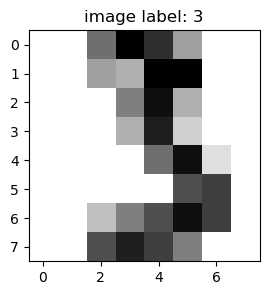

In [74]:
sample_index = 45
plt.figure(figsize=(3, 3))
plt.imshow(digits.images[sample_index], cmap=plt.cm.gray_r,
           interpolation='nearest')
plt.title("image label: %d" % digits.target[sample_index]);

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(digits.data, digits.target, test_size=0.15)
data = np.asarray(digits.data, dtype='float32')
target = np.asarray(digits.target, dtype='int32')



In [ ]:
print(X_train.data.shape)
print(y_train.data.shape)

(1527, 64)
(1527,)


In [ ]:
from sklearn import preprocessing
print(f"The mean after standardization is : {X_train.mean()}")
print(f"The standard deviation after standardization is : {X_train.std()}")
scaler = preprocessing.StandardScaler()
X_train_pp = scaler.fit_transform(X_train)
print(f"The mean after standardization is : {X_train_pp.mean()}")
print(f"The standard deviation after standardization is : {X_train_pp.std()}")

The mean after standardization is : 4.879666011787819
The standard deviation after standardization is : 6.009989562773007
The mean after standardization is : -2.908246298952604e-18
The standard deviation after standardization is : 0.9682458365518538


1


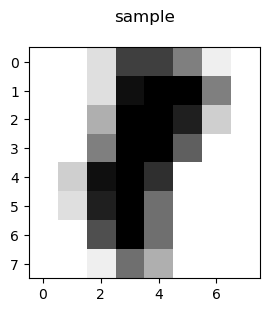

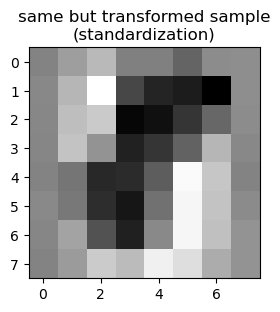

In [78]:
sample_index = 45
plt.figure(figsize=(3, 3))
plt.imshow(X_train[sample_index].reshape(8, 8),
           cmap=plt.cm.gray_r, interpolation='nearest')
plt.title("sample\n");
print(y_train[sample_index])
sample_index = 45
plt.figure(figsize=(3, 3))
plt.imshow(X_train_pp[sample_index].reshape(8, 8),
           cmap=plt.cm.gray_r, interpolation='nearest')
plt.title("same but transformed sample\n(standardization)");

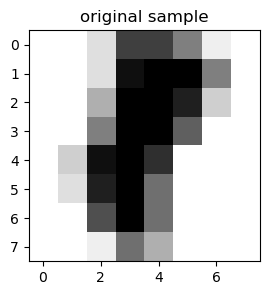

In [ ]:
import matplotlib.pyplot as plt

sample_index = 45

original_sample = scaler.inverse_transform(X_train_pp[sample_index].reshape(1, -1))
original_sample = original_sample.reshape(8, 8)  # reshape to 8x8 image

plt.figure(figsize=(3, 3))
plt.imshow(original_sample, cmap=plt.cm.gray_r, interpolation='nearest')
plt.title("original sample")
plt.show()


In [80]:
print(X_train_pp.shape, y_train.shape)

(1527, 64) (1527,)


In [81]:
print(X_test.shape, y_test.shape)

(270, 64) (270,)


In [82]:
y_train[:3]

array([0, 4, 3])

In [83]:
#Use to_categorical and print 3 first data.
from tensorflow.keras.utils import to_categorical

#Write your code here.
y_train_encoded = to_categorical(y_train)
y_test_encoded = to_categorical(y_test)

## 2. Feed Forward Neural Networks with Keras

### a. First Keras Model

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras import optimizers

input_dim = X_train_pp.shape[1]
hidden_dim = 100
output_dim = y_train_encoded.shape[1]

model = Sequential([
    Dense(16, input_dim=input_dim, activation='tanh'),
    Dense(output_dim, activation='softmax')
])



model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])


history = model.fit(X_train_pp, y_train_encoded,
                    epochs=15,
                    batch_size=32,
                    validation_split=0.2,
                    verbose=1)



Epoch 1/15


/opt/miniconda3/envs/venvMacOS/lib/python3.13/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.1810 - loss: 2.2947 - val_accuracy: 0.2778 - val_loss: 1.9858
Epoch 2/15
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.4570 - loss: 1.7373 - val_accuracy: 0.5359 - val_loss: 1.5469
Epoch 3/15
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6667 - loss: 1.3708 - val_accuracy: 0.6961 - val_loss: 1.2554
Epoch 4/15
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7576 - loss: 1.1231 - val_accuracy: 0.7876 - val_loss: 1.0494
Epoch 5/15
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8133 - loss: 0.9418 - val_accuracy: 0.8235 - val_loss: 0.8930
Epoch 6/15
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8452 - loss: 0.8045 - val_accuracy: 0.8497 - val_loss: 0.7758
Epoch 7/15
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8657 - loss: 0.6938 - val_accuracy: 0.8627 - val_loss: 0.6862
Epoch 8/15
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8903 - loss: 0.6072 - val_accuracy: 0.8725 - val_loss: 0.6107
Epo

In [ ]:

model.summary()


Model: "sequential_20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_58 (Dense)                │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_59 (Dense)                │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,632 (14.19 KB)

 Trainable params: 1,210 (4.73 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,422 (9.46 KB)

In [86]:
import pandas as pd

history_df = pd.DataFrame(history.history)
history_df["epoch"] = history.epoch

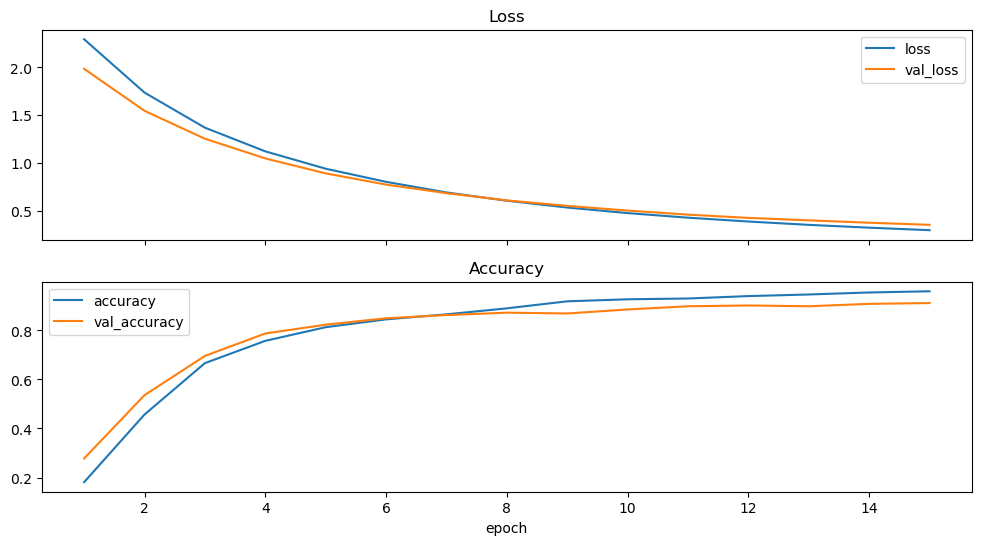

In [87]:

history_df = pd.DataFrame(history.history)
history_df["epoch"] = history_df.index + 1  # add epoch column
fig, (ax0, ax1) = plt.subplots(nrows=2, sharex=True, figsize=(12, 6))
history_df.plot(x="epoch", y=["loss", "val_loss"], ax=ax0, title="Loss")
history_df.plot(x="epoch", y=["accuracy", "val_accuracy"], ax=ax1, title="Accuracy")
plt.show()


In [88]:
optimizers.SGD?

Init signature:
optimizers.SGD(
    learning_rate=0.01,
    momentum=0.0,
    nesterov=False,
    weight_decay=None,
    clipnorm=None,
    clipvalue=None,
    global_clipnorm=None,
    use_ema=False,
    ema_momentum=0.99,
    ema_overwrite_frequency=None,
    loss_scale_factor=None,
    gradient_accumulation_steps=None,
    name='SGD',
    **kwargs,
)
Docstring:     
Gradient descent (with momentum) optimizer.

Update rule for parameter `w` with gradient `g` when `momentum` is 0:

```python
w = w - learning_rate * g
```

Update rule when `momentum` is larger than 0:

```python
velocity = momentum * velocity - learning_rate * g
w = w + velocity
```

When `nesterov=True`, this rule becomes:

```python
velocity = momentum * velocity - learning_rate * g
w = w + momentum * velocity - learning_rate * g
```

Args:
    learning_rate: A float, a
        `keras.optimizers.schedules.LearningRateSchedule` instance, or
        a callable that takes no arguments and returns the actual value to
   

Epoch 1/15
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9623 - loss: 0.2772 - val_accuracy: 0.9150 - val_loss: 0.3387
Epoch 2/15
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9672 - loss: 0.2579 - val_accuracy: 0.9216 - val_loss: 0.3215
Epoch 3/15
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9672 - loss: 0.2409 - val_accuracy: 0.9183 - val_loss: 0.3098
Epoch 4/15
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9689 - loss: 0.2247 - val_accuracy: 0.9314 - val_loss: 0.2949
Epoch 5/15
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9705 - loss: 0.2111 - val_accuracy: 0.9248 - val_loss: 0.2833
Epoch 6/15
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9713 - loss: 0.1987 - val_accuracy: 0.9248 - val_loss: 0.2739
Epoch 7/15
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9746 - loss: 0.1872 - val_accuracy: 0.9216 - val_loss: 0.2634
Epoch 8/15
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9762 - loss: 0.1764 - val_accuracy: 0.9248 - val_loss:

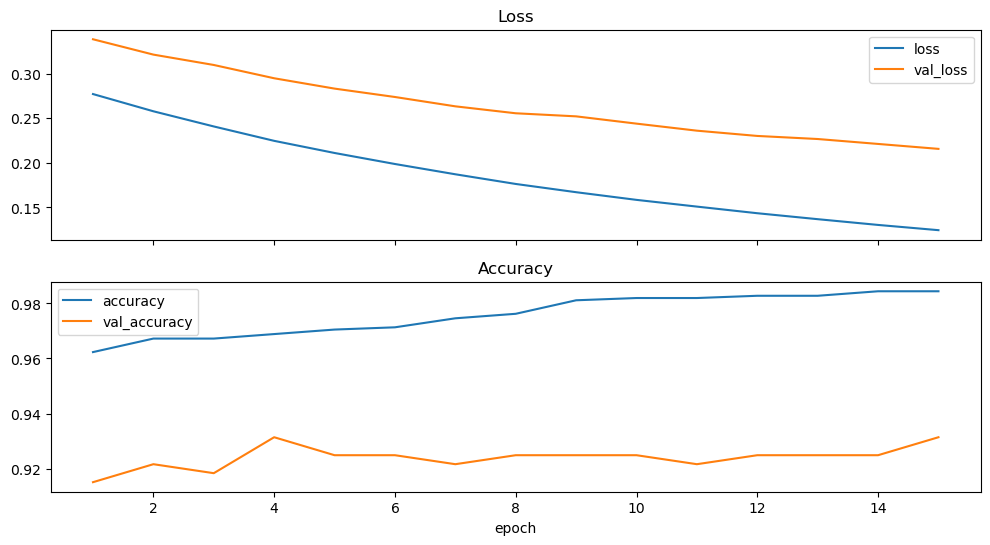

In [ ]:
opt = optimizers.SGD(learning_rate=0.001)

history2 = model.fit(X_train_pp, y_train_encoded,
                    epochs=15,
                    batch_size=32,
                    validation_split=0.2,
                    verbose=1)

history2_df = pd.DataFrame(history2.history)
history2_df["epoch"] = history2.epoch

history2_df = pd.DataFrame(history2.history)
history2_df["epoch"] = history2_df.index + 1  # add epoch column
fig, (ax0, ax1) = plt.subplots(nrows=2, sharex=True, figsize=(12, 6))
history2_df.plot(x="epoch", y=["loss", "val_loss"], ax=ax0, title="Loss")
history2_df.plot(x="epoch", y=["accuracy", "val_accuracy"], ax=ax1, title="Accuracy")
plt.show()

# With very small learning rate, the model doesn't learn anything in 15 epochs. We are enable to see progression.

In [ ]:
X_test_pp = scaler.transform(X_test)

y_predict = model.predict(X_test_pp)

test_loss, test_acc = model.evaluate(X_test_pp, y_test_encoded, verbose=0)

print(f"Loss : {test_loss}")
print(f"Accuracy : {test_acc}")

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Loss : 0.21715189516544342
Accuracy : 0.9407407641410828


In [91]:
import numpy as np

y_pred_prob = model.predict(X_test_pp)
predicted_labels_numpy = np.argmax(y_pred_prob, axis=1)
predicted_labels_numpy


9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


array([7, 8, 7, 1, 2, 0, 7, 6, 9, 7, 7, 3, 7, 3, 0, 4, 1, 0, 1, 1, 3, 0,
       5, 2, 4, 4, 8, 9, 3, 5, 3, 4, 4, 1, 6, 5, 9, 5, 7, 5, 8, 1, 8, 1,
       1, 8, 3, 6, 7, 9, 0, 9, 5, 9, 6, 5, 8, 3, 2, 4, 1, 9, 1, 1, 3, 7,
       9, 8, 8, 9, 7, 4, 4, 8, 8, 9, 5, 8, 3, 6, 1, 4, 3, 3, 8, 4, 7, 1,
       3, 0, 5, 1, 6, 5, 2, 7, 1, 1, 4, 0, 8, 6, 6, 3, 0, 3, 7, 2, 8, 7,
       1, 5, 3, 6, 8, 2, 6, 6, 0, 5, 8, 3, 6, 2, 5, 0, 4, 6, 4, 4, 7, 4,
       5, 2, 3, 2, 9, 5, 3, 4, 9, 0, 4, 0, 0, 1, 6, 4, 2, 5, 5, 7, 6, 7,
       7, 1, 8, 5, 5, 6, 3, 1, 6, 2, 6, 2, 6, 5, 5, 4, 2, 0, 7, 2, 3, 2,
       6, 3, 1, 7, 4, 4, 6, 3, 2, 3, 5, 4, 7, 5, 7, 5, 6, 2, 9, 3, 9, 8,
       4, 1, 7, 8, 2, 6, 3, 1, 2, 9, 3, 3, 4, 0, 7, 8, 1, 5, 1, 3, 8, 4,
       4, 6, 5, 3, 6, 1, 3, 6, 9, 1, 3, 0, 8, 1, 1, 5, 1, 1, 5, 1, 1, 1,
       3, 2, 2, 3, 0, 5, 6, 3, 2, 3, 3, 0, 5, 8, 9, 6, 6, 4, 6, 1, 7, 2,
       9, 7, 0, 8, 1, 9])

In [92]:
type(predicted_labels_numpy), predicted_labels_numpy.shape

(numpy.ndarray, (270,))

In [93]:
predictions_tf = model(X_test_pp)
predictions_tf[:5]

<tf.Tensor: shape=(5, 10), dtype=float32, numpy=
array([[4.03371814e-04, 7.95230153e-04, 1.74024026e-03, 4.20047389e-03,
        4.54228226e-04, 1.57432078e-04, 3.97640870e-05, 9.90075111e-01,
        1.99712857e-04, 1.93455676e-03],
       [3.13053635e-04, 4.66162302e-02, 2.57146414e-02, 4.43662331e-03,
        7.24385167e-03, 1.24843049e-04, 1.11333154e-01, 4.57571493e-03,
        7.95752287e-01, 3.88958375e-03],
       [9.29047703e-04, 1.13258476e-03, 6.11507194e-03, 6.28542388e-03,
        2.31254729e-03, 3.68653098e-03, 7.43731973e-04, 9.75951731e-01,
        2.20813113e-03, 6.35175325e-04],
       [1.19913230e-03, 8.28482687e-01, 8.15715641e-03, 1.20387611e-03,
        5.35867736e-03, 1.38439937e-04, 1.85990147e-03, 2.13462580e-02,
        1.27915040e-01, 4.33865609e-03],
       [4.13694652e-04, 3.62238854e-01, 4.96474564e-01, 1.70347113e-02,
        1.19386297e-02, 1.50005697e-04, 1.17877759e-02, 1.48013616e-02,
        8.40677023e-02, 1.09272276e-03]], dtype=float32)>

In [94]:
type(predictions_tf), predictions_tf.shape

(tensorflow.python.framework.ops.EagerTensor, TensorShape([270, 10]))

In [95]:
import tensorflow as tf

tf.reduce_sum(predictions_tf, axis=1)[:5]

<tf.Tensor: shape=(5,), dtype=float32, numpy=
array([1.0000001, 1.       , 1.       , 0.9999999, 1.       ],
      dtype=float32)>

In [96]:
predicted_labels_tf = tf.argmax(predictions_tf, axis=1)
predicted_labels_tf[:5]

<tf.Tensor: shape=(5,), dtype=int64, numpy=array([7, 8, 7, 1, 2])>

In [97]:
accuracy_tf = tf.reduce_mean(tf.cast(predicted_labels_tf == y_test, tf.float64))
accuracy_tf

<tf.Tensor: shape=(), dtype=float64, numpy=0.9407407407407408>

In [98]:
#for converting tensor to numpy array
array = accuracy_tf.numpy()
array

np.float64(0.9407407407407408)

In [99]:
predicted_labels_tf[:5]

<tf.Tensor: shape=(5,), dtype=int64, numpy=array([7, 8, 7, 1, 2])>

In [100]:
predicted_labels_tf.numpy()[:5]

array([7, 8, 7, 1, 2])

## 3. Impact of Initialization

In [101]:
from tensorflow.keras import initializers

normal_init = initializers.TruncatedNormal(stddev=0.01)


model = Sequential()
model.add(Dense(hidden_dim, input_dim=input_dim, activation="tanh",
                kernel_initializer=normal_init))
model.add(Dense(hidden_dim, activation="tanh",
                kernel_initializer=normal_init))
model.add(Dense(output_dim, activation="softmax",
                kernel_initializer=normal_init))

model.compile(optimizer=optimizers.SGD(learning_rate=0.1),
              loss='categorical_crossentropy', metrics=['accuracy'])



/opt/miniconda3/envs/venvMacOS/lib/python3.13/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [102]:
model.layers

[<Dense name=dense_60, built=True>,
 <Dense name=dense_61, built=True>,
 <Dense name=dense_62, built=True>]

In [103]:
model.layers[0].weights

[<Variable path=sequential_21/dense_60/kernel, shape=(64, 100), dtype=float32, value=[[-0.01803034 -0.01808834  0.01642406 ...  0.00483712 -0.00388143
    0.01425487]
  [ 0.0091911  -0.00927695 -0.00833663 ... -0.01004557 -0.00516285
   -0.00094984]
  [ 0.00151009 -0.01471797  0.00294357 ... -0.00614035  0.00742232
    0.0085503 ]
  ...
  [-0.0039042  -0.00648902 -0.01125968 ...  0.01416901  0.00184253
    0.00080675]
  [ 0.01489882 -0.01242601  0.0189894  ... -0.00595412 -0.00890429
   -0.00282484]
  [-0.00228966 -0.00544468  0.01367887 ...  0.00141815  0.01368048
   -0.0093834 ]]>,
 <Variable path=sequential_21/dense_60/bias, shape=(100,), dtype=float32, value=[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0.]>]

In [104]:
w = model.layers[0].weights[0]
w

<Variable path=sequential_21/dense_60/kernel, shape=(64, 100), dtype=float32, value=[[-0.01803034 -0.01808834  0.01642406 ...  0.00483712 -0.00388143
   0.01425487]
 [ 0.0091911  -0.00927695 -0.00833663 ... -0.01004557 -0.00516285
  -0.00094984]
 [ 0.00151009 -0.01471797  0.00294357 ... -0.00614035  0.00742232
   0.0085503 ]
 ...
 [-0.0039042  -0.00648902 -0.01125968 ...  0.01416901  0.00184253
   0.00080675]
 [ 0.01489882 -0.01242601  0.0189894  ... -0.00595412 -0.00890429
  -0.00282484]
 [-0.00228966 -0.00544468  0.01367887 ...  0.00141815  0.01368048
  -0.0093834 ]]>

In [105]:
b = model.layers[0].weights[1]
b

<Variable path=sequential_21/dense_60/bias, shape=(100,), dtype=float32, value=[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0.]>

Epoch 1/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 794us/step - accuracy: 0.1094 - loss: 2.3027
Epoch 2/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1290 - loss: 2.2988
Epoch 3/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.2502 - loss: 2.2708 
Epoch 4/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 622us/step - accuracy: 0.2423 - loss: 1.9080
Epoch 5/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 615us/step - accuracy: 0.5573 - loss: 1.4099
Epoch 6/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 619us/step - accuracy: 0.7276 - loss: 0.8651
Epoch 7/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 621us/step - accuracy: 0.7682 - loss: 0.6725
Epoch 8/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 644us/step - accuracy: 0.8206 - loss: 0.5589
Epoch 9/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 607us/step - accuracy: 0.8684 - loss: 0.4380
Epoch 10/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 619us/step - accuracy: 0.9064 - loss: 0.3390
Epoch 11/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 637us/step - accuracy: 0.9208 - loss: 0.2785
Epoch 12/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 624us/step - 

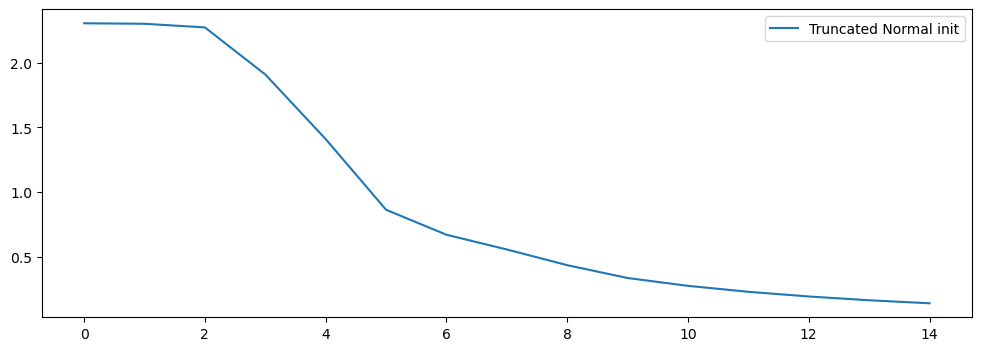

In [106]:
history = model.fit(X_train_pp, y_train_encoded, epochs=15, batch_size=32)

plt.figure(figsize=(12, 4))
plt.plot(history.history['loss'], label="Truncated Normal init")
plt.legend();

In [107]:
model.layers[0].weights

[<Variable path=sequential_21/dense_60/kernel, shape=(64, 100), dtype=float32, value=[[-0.01803034 -0.01808834  0.01642406 ...  0.00483712 -0.00388143
    0.01425487]
  [ 0.02498564 -0.02999495 -0.00119812 ... -0.0047818  -0.02116257
    0.00324038]
  [-0.00824372 -0.06047046  0.02445021 ...  0.01203723  0.02599878
    0.00376609]
  ...
  [ 0.02816434 -0.01179316 -0.074891   ...  0.03285229 -0.03112475
    0.0110305 ]
  [ 0.01441709 -0.00854768 -0.00236752 ... -0.02989287 -0.03443754
    0.0113818 ]
  [ 0.01678185  0.02004866 -0.01416823 ...  0.04513873  0.06021785
   -0.01808234]]>,
 <Variable path=sequential_21/dense_60/bias, shape=(100,), dtype=float32, value=[-6.64206818e-02 -9.35433730e-02 -2.69932952e-03  1.75792240e-02
   3.78433205e-02  7.38030449e-02 -1.45761343e-02 -7.58818723e-03
  -2.13493872e-02 -4.19530682e-02 -1.21740124e-03  2.14569326e-02
  -7.80035974e-03 -2.62948424e-02 -6.28625453e-02 -1.52784316e-02
   8.96333605e-02 -2.33670957e-02 -7.35231787e-02 -5.08383140e-02


In [108]:

# Your code here
from tensorflow.keras import optimizers, initializers
TF_USE_LEGACY_KERAS=True
init_schemes = {
    "Very Small (1e-3)": initializers.RandomNormal(stddev=1e-3),
    "Large Scale (10)": initializers.RandomNormal(stddev=10.0),
    "Zeros": initializers.Zeros(),
    "Xavier (Default)": initializers.GlorotNormal()
}

for init_name, init_val in init_schemes.items():
    print(f"Testing SGD with {init_name}...")
    
    # Build model
    model = Sequential([
        Dense(hidden_dim, input_dim=input_dim, activation="tanh", kernel_initializer=init_val),
        Dense(hidden_dim, activation="tanh", kernel_initializer=init_val),
        Dense(output_dim, activation="softmax", kernel_initializer=init_val)
    ])
    opti = optimizers.SGD(learning_rate=0.01)
    model.compile(optimizer=opti, loss='categorical_crossentropy', metrics=['accuracy'])        
    # Train for 10 epochs
    history = model.fit(X_train_pp, y_train_encoded, epochs=10, batch_size=32, verbose=0)
    print(history.history['accuracy'])
    print(f"Accuracy: {history.history['accuracy'][-1]:.4f}")

Testing SGD with Very Small (1e-3)...
[0.08578912913799286, 0.10543549805879593, 0.0956123098731041, 0.10543549805879593, 0.10281597822904587, 0.09430255740880966, 0.09954158216714859, 0.10543549805879593, 0.10543549805879593, 0.10085134208202362]
Accuracy: 0.1009
Testing SGD with Large Scale (10)...
[0.09823182970285416, 0.12115258723497391, 0.12704649567604065, 0.13686968386173248, 0.14472822844982147, 0.1499672532081604, 0.15913556516170502, 0.17812705039978027, 0.18074655532836914, 0.1879502236843109]
Accuracy: 0.1880
Testing SGD with Zeros...
[0.08447936922311783, 0.0916830375790596, 0.09692206978797913, 0.10543549805879593, 0.10543549805879593, 0.10543549805879593, 0.10543549805879593, 0.10543549805879593, 0.10543549805879593, 0.10543549805879593]
Accuracy: 0.1054
Testing SGD with Xavier (Default)...
[0.49770793318748474, 0.7924033999443054, 0.8690242171287537, 0.8952193856239319, 0.9122462272644043, 0.9233791828155518, 0.9312376976013184, 0.939751148223877, 0.9489194750785828, 0

In [ ]:
# The default is the best one by far. Otherwise, other initialization schemes result to very bad performance.

## 4. Callback
              

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
print(f"Testing SGD with Early Stopping/Callback...")
    
early_stop = EarlyStopping(
    monitor='val_loss',      
    patience=5,            
    restore_best_weights=True, 
    verbose=1
)
model = Sequential([
    Dense(hidden_dim, input_dim=input_dim, activation="tanh", kernel_initializer=initializers.GlorotNormal()),
    Dense(hidden_dim, activation="tanh", kernel_initializer=initializers.GlorotNormal()),
    Dense(output_dim, activation="softmax", kernel_initializer=initializers.GlorotNormal())
])
opti = optimizers.SGD(learning_rate=0.01)
model.compile(optimizer=opti, loss='categorical_crossentropy', metrics=['accuracy'])        
history = model.fit(X_train_pp, y_train_encoded, epochs=50, batch_size=32, verbose=0, callbacks=[early_stop])
print(history.history['accuracy'])
print(f"Accuracy: {history.history['accuracy'][-1]:.4f}")

print(f"Testing SGD without Early Stopping/Callback...")     
history = model.fit(X_train_pp, y_train_encoded, epochs=50, batch_size=32, verbose=0)
print(history.history['accuracy'])
print(f"Accuracy: {history.history['accuracy'][-1]:.4f}")

Testing SGD with Early Stopping/Callback...


/opt/miniconda3/envs/venvMacOS/lib/python3.13/site-packages/keras/src/callbacks/early_stopping.py:99: UserWarning: Early stopping conditioned on metric `val_loss` which is not available. Available metrics are: accuracy,loss
  current = self.get_monitor_value(logs)


[0.4007858633995056, 0.7511460185050964, 0.8493778705596924, 0.8867059350013733, 0.9050425887107849, 0.9194499254226685, 0.9286181926727295, 0.9345121383666992, 0.9377865195274353, 0.943025529384613, 0.9456450343132019, 0.9502292275428772, 0.9541584849357605, 0.9561231136322021, 0.9607072472572327, 0.9626718759536743, 0.965291440486908, 0.965291440486908, 0.9666011929512024, 0.9692206978797913, 0.9705304503440857, 0.9705304503440857, 0.974459707736969, 0.9751145839691162, 0.9757694602012634, 0.9757694602012634, 0.9777341485023499, 0.9777341485023499, 0.9790439009666443, 0.9810085296630859, 0.984282910823822, 0.9816634058952332, 0.9836280345916748, 0.9855926632881165, 0.9849377870559692, 0.9862475395202637, 0.9862475395202637, 0.9875572919845581, 0.9875572919845581, 0.9888670444488525, 0.9895219206809998, 0.9888670444488525, 0.9888670444488525, 0.990176796913147, 0.9908316731452942, 0.9908316731452942, 0.9908316731452942, 0.9914865493774414, 0.9908316731452942, 0.9914865493774414]
Accur

In [ ]:
# I can observe that early stopping/Callback is enough useful to consider that the model is almost converged after 10 epochs. Depending on the subject we can limit the number of epochs and gaining in time and compute.


In [ ]:
import datetime
log_dir = "logs/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")

from tensorflow.keras.callbacks import TensorBoard
tensorboard_callback = TensorBoard(
    log_dir=log_dir, 
    histogram_freq=1,      
    write_graph=True,     
    update_freq='epoch'    
)

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

model.fit(
    X_train_pp, y_train_encoded, 
    epochs=20, 
    batch_size=32, 
    validation_split=0.2,
    callbacks=[tensorboard_callback] 
)

Epoch 1/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9959 - loss: 0.0427 - val_accuracy: 0.9771 - val_loss: 0.0505
Epoch 2/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9967 - loss: 0.0276 - val_accuracy: 0.9869 - val_loss: 0.0487
Epoch 3/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9975 - loss: 0.0186 - val_accuracy: 0.9804 - val_loss: 0.0573
Epoch 4/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 0.0138 - val_accuracy: 0.9837 - val_loss: 0.0530
Epoch 5/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 0.0103 - val_accuracy: 0.9771 - val_loss: 0.0576
Epoch 6/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 0.0083 - val_accuracy: 0.9771 - val_loss: 0.0567
Epoch 7/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 0.0070 - val_accuracy: 0.9771 - val_loss: 0.0605
Epoch 8/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 0.0059 - val_accuracy: 0.9771 - val_loss:

In [113]:
%load_ext tensorboard
%tensorboard --logdir logs
   


The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 73187), started 8:25:24 ago. (Use '!kill 73187' to kill it.)

What is functionality of tensorborad?

In [114]:
#Your Analysis here
# The functionality of tensorboard is to get deep insights about the training process. It is display in visualization. We can deep dive into the training process with a tremendous interactive GUI.

## Part 2: Sckilearn

### Goals: 
- Intro: train a neural network with `Sklearn` and MLPClassifier
- https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html#sklearn.neural_network.MLPClassifier
- We use the same strategy and previous dataset.

Use the previous dataset and standardScalar for preprocessing.
Implement MLPClassifier with 500 iteration and activation='relu'and train it.
Use model predection.
Print the confusion matrix.


In [117]:
#Your code here.
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, accuracy_score
clf = MLPClassifier(random_state=1, max_iter=500, activation='relu').fit(X_train_pp, y_train)

y_pred_sklearn = clf.predict(X_test_pp)

print(confusion_matrix(y_test, y_pred_sklearn))
print(f"Accuracy: {accuracy_score(y_test, y_pred_sklearn)}")



[[19  0  0  0  0  0  0  0  0  0]
 [ 0 35  0  0  0  0  0  0  0  0]
 [ 0  0 26  0  1  0  0  0  0  0]
 [ 0  0  0 34  0  0  0  0  0  0]
 [ 0  0  0  0 25  0  0  0  0  0]
 [ 0  0  0  0  0 28  0  0  0  1]
 [ 0  0  0  0  0  0 30  0  0  0]
 [ 0  0  0  0  0  0  0 27  0  0]
 [ 0  1  0  0  0  0  0  0 24  0]
 [ 0  0  0  0  0  0  0  0  1 18]]
Accuracy: 0.9851851851851852


At which iteration did the model stop?

In [119]:
#Your code here.

print(f"The model stopped at {clf.n_iter_} epochs")

The model stopped at 136 epochs


Can you explain the main differences between this model (scikit-learn MLP) and one built with Keras? Can we use this model for all neural network problems?

In [ ]:
# Your anlysis here
# The main differences between the two models is that we implented a simple MLP while with keras it's a more complex one.